Running Value Iteration...
Value Iteration Completed.

Running Q-Learning across 50 seeds...
Seed  0 | Q-Error: 0.1569 | V-Error: 0.1519 | Mismatch: 14.76%
Seed  1 | Q-Error: 0.1097 | V-Error: 0.1048 | Mismatch: 14.29%
Seed  2 | Q-Error: 0.1248 | V-Error: 0.1209 | Mismatch: 15.00%
Seed  3 | Q-Error: 0.1125 | V-Error: 0.1122 | Mismatch: 17.14%
Seed  4 | Q-Error: 0.1804 | V-Error: 0.1753 | Mismatch: 15.71%
Seed  5 | Q-Error: 0.1347 | V-Error: 0.1297 | Mismatch: 13.10%
Seed  6 | Q-Error: 0.0991 | V-Error: 0.0946 | Mismatch: 13.33%
Seed  7 | Q-Error: 0.1348 | V-Error: 0.1298 | Mismatch: 15.24%
Seed  8 | Q-Error: 0.1332 | V-Error: 0.1281 | Mismatch: 14.05%
Seed  9 | Q-Error: 0.1356 | V-Error: 0.1306 | Mismatch: 17.38%
Seed 10 | Q-Error: 0.1065 | V-Error: 0.1020 | Mismatch: 14.76%
Seed 11 | Q-Error: 0.1085 | V-Error: 0.1035 | Mismatch: 14.52%
Seed 12 | Q-Error: 0.1344 | V-Error: 0.1293 | Mismatch: 16.90%
Seed 13 | Q-Error: 0.1153 | V-Error: 0.1103 | Mismatch: 16.43%
Seed 14 | Q-Error: 0.1303

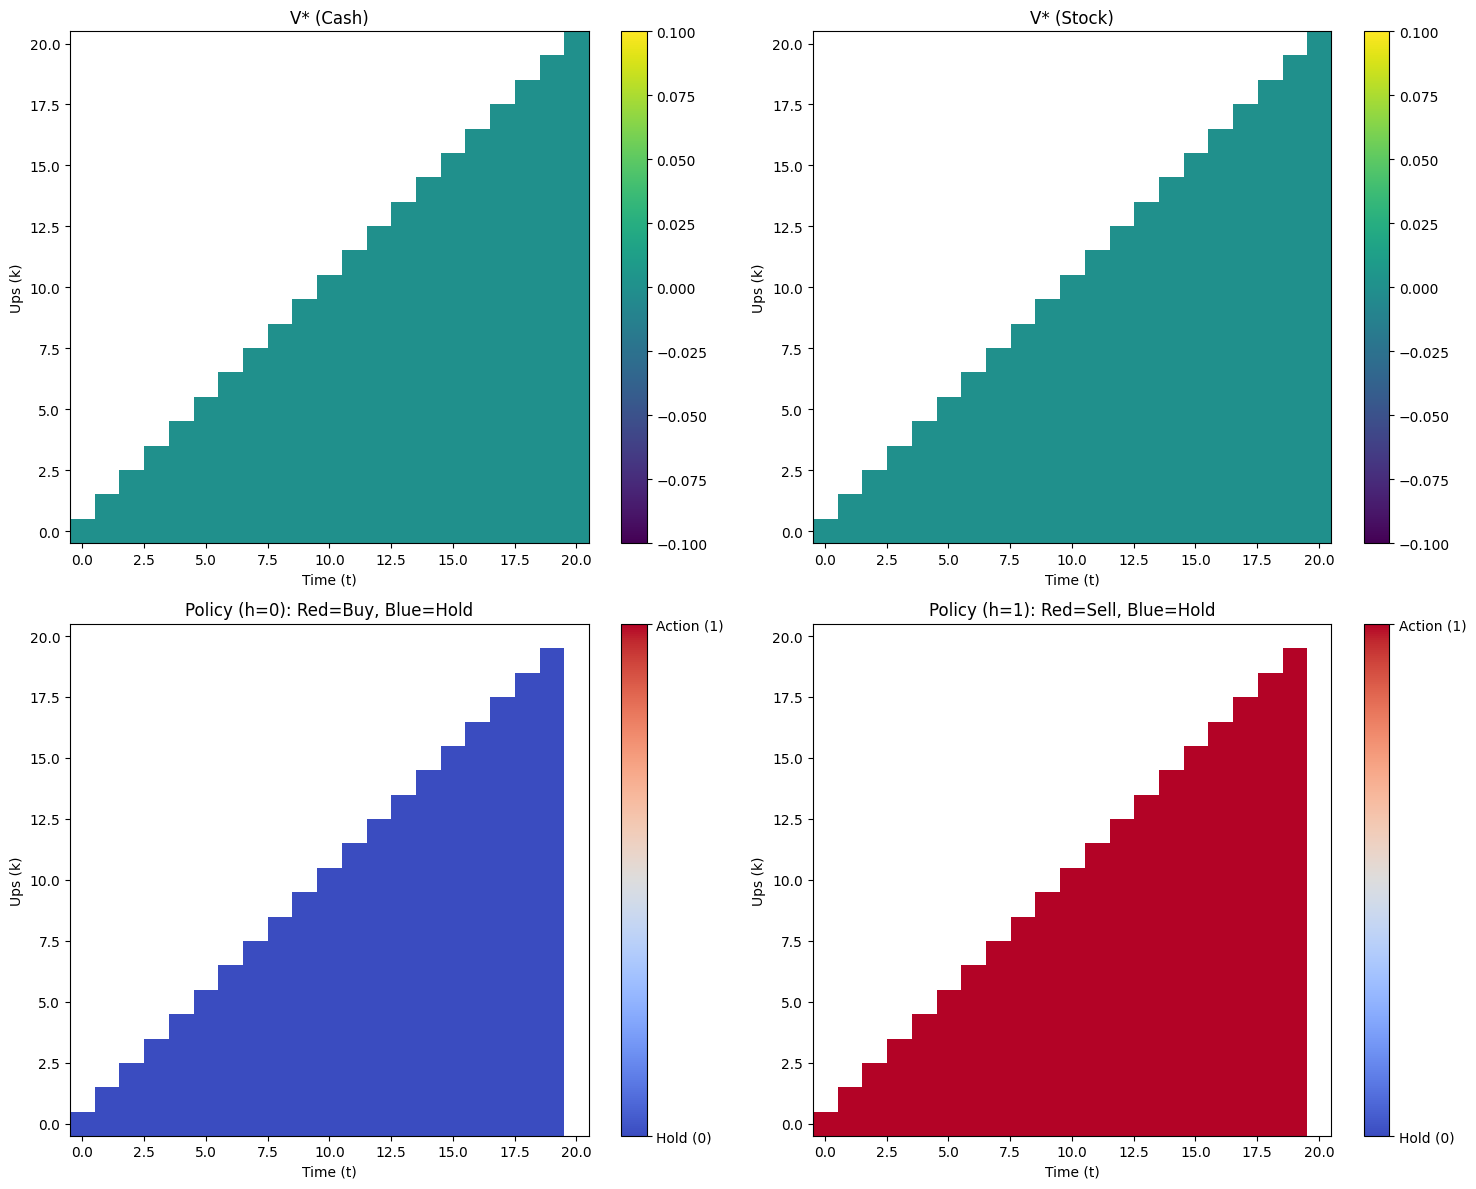

In [30]:
import numpy as np
import math
import random
from collections import defaultdict
import matplotlib.pyplot as plt

#1. Implementation of the Environment
class StockTradingEnv:
    def __init__(self):
        self.H = 20 #finite time horizon 20
        self.S0 = 100.0 #initial stock price S0
        self.u = 1.1 #increase factor
        self.d = 0.9 #decrease factor
        self.p = 0.5 #probability of increase
        self.gamma = 1.0 #discount factor

        self.log_u = math.log(self.u) #reward when increase
        self.log_d = math.log(self.d) #reward when decrease

        # Initial State Representation: (t, k, h)
        self.state = (0, 0, 0) #set to all 0s

    def reset(self):
        self.state = (0, 0, 0)
        return self.state

    def get_valid_actions(self, h):
        #Valid set of actions at each state
        if h == 0: #have in money
            return ['buy', 'hold']
        elif h == 1: #have in stock
            return ['sell', 'hold']
        else:
            raise ValueError("Invalid holding status")

    def get_next_holding_status(self, h, action):
        #Getting the next holding state based on the action from previous state
        if h == 0:
            if action == 'buy': return 1
            elif action == 'hold': return 0
        elif h == 1:
            if action == 'sell': return 0
            elif action == 'hold': return 1
        raise ValueError("Invalid action for current holding status")

    #One step in the value iteration
    def step(self, action):
        t, k, h = self.state

        # Check if action is valid for current state
        valid_actions = self.get_valid_actions(h)
        if action not in valid_actions:
            raise ValueError(f"Action '{action}' is invalid for state {self.state}")

        # getting the next state
        h_next = self.get_next_holding_status(h, action)

        # Random decision proccess for deciding the stock price
        is_up = np.random.rand() < self.p

        if is_up:
            k_next = k + 1 #number of upward price moves increased by one
            reward = self.log_u if h_next == 1 else 0.0 #reward for having stock when price is up
        else:
            k_next = k
            reward = self.log_d if h_next == 1 else 0.0 #reward for having stock when price is down

        t_next = t + 1
        self.state = (t_next, k_next, h_next)
        done = (t_next == self.H)

        return self.state, reward, done, {}

#2. Implementation of Value Iteration (Benchmark Case)
def run_value_iteration(env):
    #Set up default Q and V functions and policy
    V = defaultdict(float)
    Q = defaultdict(lambda: defaultdict(float))
    Policy = {}

    # Terminal states (t = H)
    for k in range(env.H + 1):
        for h in [0, 1]:
            V[(env.H, k, h)] = 0.0

    # Backward induction (t = H-1 down to 0)
    for t in range(env.H - 1, -1, -1):
        for k in range(t + 1):
            for h in [0, 1]:
                state = (t, k, h)
                valid_actions = env.get_valid_actions(h)

                best_val = -float('inf')
                best_action = None

                for action in valid_actions:
                    h_next = env.get_next_holding_status(h, action)

                    # Up expected value
                    r_up = env.log_u if h_next == 1 else 0.0
                    v_up = V[(t+1, k+1, h_next)]

                    # Down expected value
                    r_down = env.log_d if h_next == 1 else 0.0
                    v_down = V[(t+1, k, h_next)]

                    # Q(s, a)
                    q_val = env.p * (r_up + env.gamma * v_up) + (1 - env.p) * (r_down + env.gamma * v_down)
                    Q[state][action] = q_val

                    # tie-breaking rule, only replace and it is greater, not when equal
                    if q_val > best_val:
                        best_val = q_val
                        best_action = action

                V[state] = best_val
                Policy[state] = best_action

    return Q, V, Policy # optimal action-value function, optimal value function, optimal policy

# 3. Tabular Q-Learning Agent with epsilon-greedy exploration
class QLearningAgent:
    def __init__(self, env, alpha=0.1, epsilon=0.1):
        self.env = env
        self.alpha = alpha #learning rate parameter
        self.epsilon = epsilon #epsilon parameter
        # Initialize Q values with 0
        self.Q = defaultdict(lambda: defaultdict(float))

    def get_action(self, state, explore=True):
        t, k, h = state
        valid_actions = self.env.get_valid_actions(h)

        # Epsilon-Greedy exploration (유효한 행동 내에서만 랜덤 선택)
        if explore and random.random() < self.epsilon:
            return random.choice(valid_actions)

        # Greedy Action
        best_val = -float('inf')
        best_actions = []
        for a in valid_actions:
            q_val = self.Q[state][a]
            if q_val > best_val:
                best_val = q_val
                best_actions = [a]
            elif q_val == best_val:
                best_actions.append(a)

        # When there is a tie, take a random action between the tied actions
        return random.choice(best_actions)

    def update(self, state, action, reward, next_state, done):
        # Q-value in next step
        if done: #terminal state --> 0
            max_next_q = 0.0
        else:
            _, _, next_h = next_state
            valid_next_actions = self.env.get_valid_actions(next_h)
            max_next_q = max([self.Q[next_state][a] for a in valid_next_actions])

        # TD Target, Q update
        td_target = reward + self.env.gamma * max_next_q
        td_error = td_target - self.Q[state][action]
        self.Q[state][action] += self.alpha * td_error


# 4. Training / Evaluation (For Hyperparameter Search)

def train_q_learning(env, num_episodes=100000, alpha_func=None, epsilon_func=None):
    agent = QLearningAgent(env)

    for episode in range(num_episodes):
        # Apply Scheduler
        if alpha_func:
            agent.alpha = alpha_func(episode, num_episodes)
        if epsilon_func:
            agent.epsilon = epsilon_func(episode, num_episodes)

        state = env.reset()
        done = False

        while not done:
            action = agent.get_action(state, explore=True)
            next_state, reward, done, _ = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state

    return agent.Q


# 5. Performance Metric Calculation
def evaluate_q_learning(env, Q_VI, V_VI, Policy_VI, Q_QL):
    #Compare Q-learning with Value Iteration (perfect case in this problem
    q_error = 0.0
    v_error = 0.0
    mismatch_count = 0
    nonterm_states_count = 0

    # Policy
    Policy_QL = {}
    V_QL = {}

    for t in range(env.H):
        for k in range(t + 1):
            for h in [0, 1]:
                state = (t, k, h)
                valid_actions = env.get_valid_actions(h)
                nonterm_states_count += 1

                # (A) Q-function error
                for a in valid_actions:
                    err = abs(Q_VI[state][a] - Q_QL[state][a])
                    if err > q_error:
                        q_error = err

                # (B) Value-function error, Greedy Policy
                best_q = -float('inf')
                best_action = None
                for a in valid_actions:
                    if Q_QL[state][a] > best_q:
                        best_q = Q_QL[state][a]
                        best_action = a
                V_QL[state] = best_q
                Policy_QL[state] = best_action

                v_err = abs(V_VI[state] - V_QL[state])
                if v_err > v_error:
                    v_error = v_err

                # (C) Policy Mismatch
                if Policy_VI[state] != Policy_QL[state]:
                    mismatch_count += 1

    policy_mismatch_rate = mismatch_count / nonterm_states_count

    return q_error, v_error, policy_mismatch_rate

def plot_optimal_results(env, V, Policy):
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    v_grids = [np.full((env.H + 1, env.H + 1), np.nan) for _ in range(2)]
    p_grids = [np.full((env.H + 1, env.H + 1), np.nan) for _ in range(2)]

    for t in range(env.H + 1):
        for k in range(t + 1):
            for h in [0, 1]:
                v_grids[h][k, t] = V[(t, k, h)]
                if t < env.H:
                    action = Policy[(t, k, h)]
                    p_grids[h][k, t] = 1 if action in ['buy', 'sell'] else 0

    titles = ["V* (Cash)", "V* (Stock)", "Policy (h=0): Red=Buy, Blue=Hold", "Policy (h=1): Red=Sell, Blue=Hold"]
    for i, ax in enumerate(axes.flat):
        if i < 2:
            im = ax.imshow(v_grids[i], origin='lower', cmap='viridis', aspect='auto')
            fig.colorbar(im, ax=ax)
        else:
            im = ax.imshow(p_grids[i-2], origin='lower', cmap='coolwarm', aspect='auto', vmin=0, vmax=1)
            cbar = fig.colorbar(im, ax=ax, ticks=[0, 1])
            cbar.ax.set_yticklabels(['Hold (0)', 'Action (1)'])
        ax.set_title(titles[i])
        ax.set_xlabel("Time (t)")
        ax.set_ylabel("Ups (k)")
    plt.tight_layout()
    plt.show()

#Actual Running of the functions above (Main Function)
if __name__ == "__main__":
    env = StockTradingEnv()

    # 1. Exact Solution (Value Iteration)
    print("Running Value Iteration...")
    Q_VI, V_VI, Policy_VI = run_value_iteration(env)
    print("Value Iteration Completed.\n")

    # 2. Hyperparameter Schedule 정의 (Linear in this running example)
    def linear_decay_epsilon(episode, total_episodes):
        return max(0.01, 1.0 - episode / (total_episodes))

    def linear_decay_alpha(episode, total_episodes):
        return max(0.01, 0.5 - episode / (total_episodes))

    # 3. Q-Learning
    seeds = list(range(0,50)) #seed requirement met (0....49)
    metrics = {'q_error': [], 'v_error': [], 'policy_mismatch': []}

    print("Running Q-Learning across 50 seeds...")
    for seed in seeds:
        np.random.seed(seed)
        random.seed(seed)

        # 100,000 max episodes
        Q_QL = train_q_learning(env, num_episodes=100000,
                                alpha_func=linear_decay_alpha,
                                epsilon_func=linear_decay_epsilon)

        q_err, v_err, mismatch = evaluate_q_learning(env, Q_VI, V_VI, Policy_VI, Q_QL)
        metrics['q_error'].append(q_err)
        metrics['v_error'].append(v_err)
        metrics['policy_mismatch'].append(mismatch)

        print(f"Seed {seed:2d} | Q-Error: {q_err:.4f} | V-Error: {v_err:.4f} | Mismatch: {mismatch*100:.2f}%")

    # 4. Return average and standard deviation (1 unit)
    print("\n--- Final Results (Average over 50 runs) ---")
    print(f"Q-Error:          {np.mean(metrics['q_error']):.4f} ± {np.std(metrics['q_error']):.4f}")
    print(f"V-Error:          {np.mean(metrics['v_error']):.4f} ± {np.std(metrics['v_error']):.4f}")
    print(f"Policy Mismatch:  {np.mean(metrics['policy_mismatch'])*100:.2f}% ± {np.std(metrics['policy_mismatch'])*100:.2f}%")

    plot_optimal_results(env, V_VI, Policy_VI)

Testing Scheduler: Constant (Alpha=0.1, Eps=0.1)...
Testing Scheduler: Linear Decay...
Testing Scheduler: Exponential Decay...


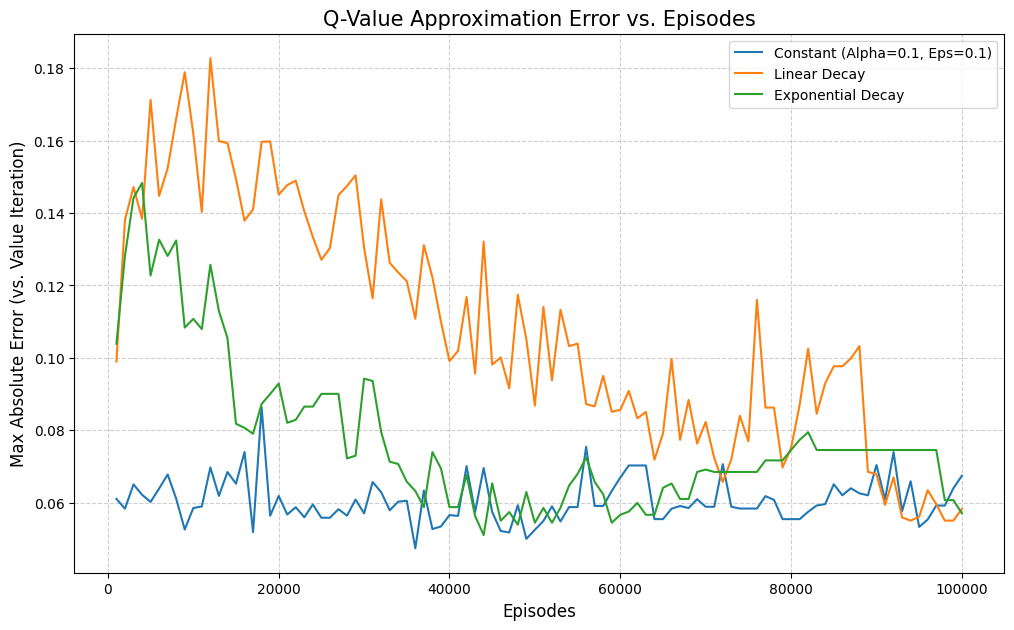

In [27]:



def get_schedulers():
    schedulers = {
        'Constant (Alpha=0.1, Eps=0.1)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: 0.1
        },
        'Linear Decay': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total))
        },
        'Exponential Decay': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (0.995 ** (ep / 100)))
        }
    }
    return schedulers



def train_and_track_error(env, Q_VI, num_episodes, alpha_f, eps_f, check_interval=1000):
    agent = QLearningAgent(env)
    errors = []
    episodes_axis = []

    for episode in range(num_episodes):
        agent.alpha = alpha_f(episode, num_episodes)
        agent.epsilon = eps_f(episode, num_episodes)

        state = env.reset()
        done = False
        while not done:
            action = agent.get_action(state, explore=True)
            next_state, reward, done, _ = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state

        # Get Q value and max error for each episode
        if (episode + 1) % check_interval == 0:
            max_err = 0
            for s in Q_VI:
                for a in Q_VI[s]:
                    err = abs(Q_VI[s][a] - agent.Q[s][a])
                    if err > max_err: max_err = err
            errors.append(max_err)
            episodes_axis.append(episode + 1)

    return episodes_axis, errors



def run_experiment():
    env = StockTradingEnv()
    Q_VI, V_VI, Policy_VI = run_value_iteration(env)

    total_episodes = 100000
    schedulers = get_schedulers()

    plt.figure(figsize=(12, 7))

    for name, funcs in schedulers.items():
        print(f"Testing Scheduler: {name}...")
        eps_axis, err_history = train_and_track_error(
            env, Q_VI, total_episodes, funcs['alpha'], funcs['epsilon']
        )
        plt.plot(eps_axis, err_history, label=name)

    plt.title('Q-Value Approximation Error vs. Episodes', fontsize=15)
    plt.xlabel('Episodes', fontsize=12)
    plt.ylabel('Max Absolute Error (vs. Value Iteration)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

if __name__ == "__main__":
    run_experiment()

Testing Scheduler: Constant (Alpha=0.1, Eps=0.9)...
Testing Scheduler: Constant (Alpha=0.1, Eps=0.5)...
Testing Scheduler: Constant (Alpha=0.1, Eps=0.1)...


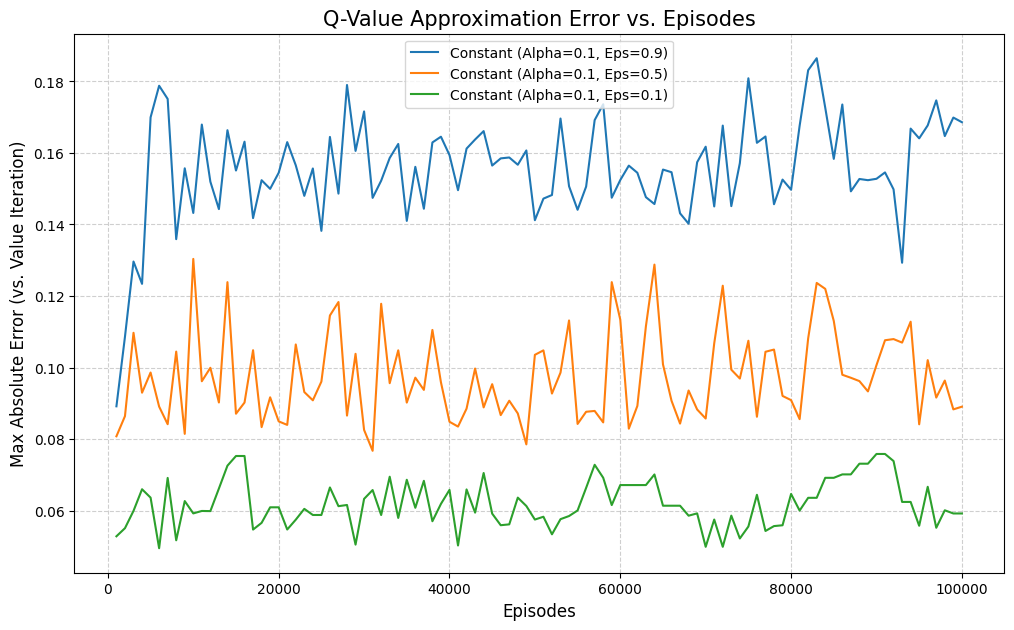

In [21]:
def get_schedulers():
    schedulers = {
        # Almost exploration
        'Constant (Alpha=0.1, Eps=0.9)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: 0.9
        },
        #Balanced
        'Constant (Alpha=0.1, Eps=0.5)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: 0.5
        },
        #Mostly exploit
        'Constant (Alpha=0.1, Eps=0.1)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: 0.1
        }
    }
    return schedulers

run_experiment()

Testing Scheduler: Linear Decay (slow)...
Testing Scheduler: Linear Decay (fast)...
Testing Scheduler: Constant (Alpha=0.1, Eps=0.1)...


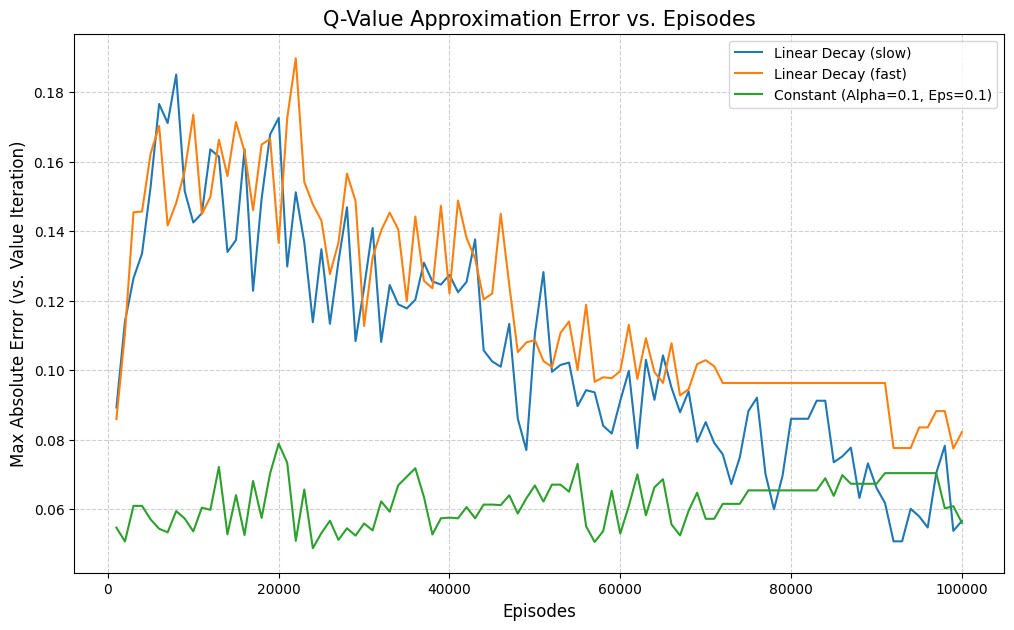

In [26]:
def get_schedulers():
    schedulers = {
        'Linear Decay (slow)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total))
        },
        'Linear Decay (fast)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        },
        #Mostly exploit
        'Constant (Alpha=0.1, Eps=0.1)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: 0.1
        }
    }
    return schedulers

run_experiment()

Testing Scheduler: Linear Decay (slow)...
Testing Scheduler: Linear Decay (fast)...
Testing Scheduler: Constant (Alpha=0.1)...


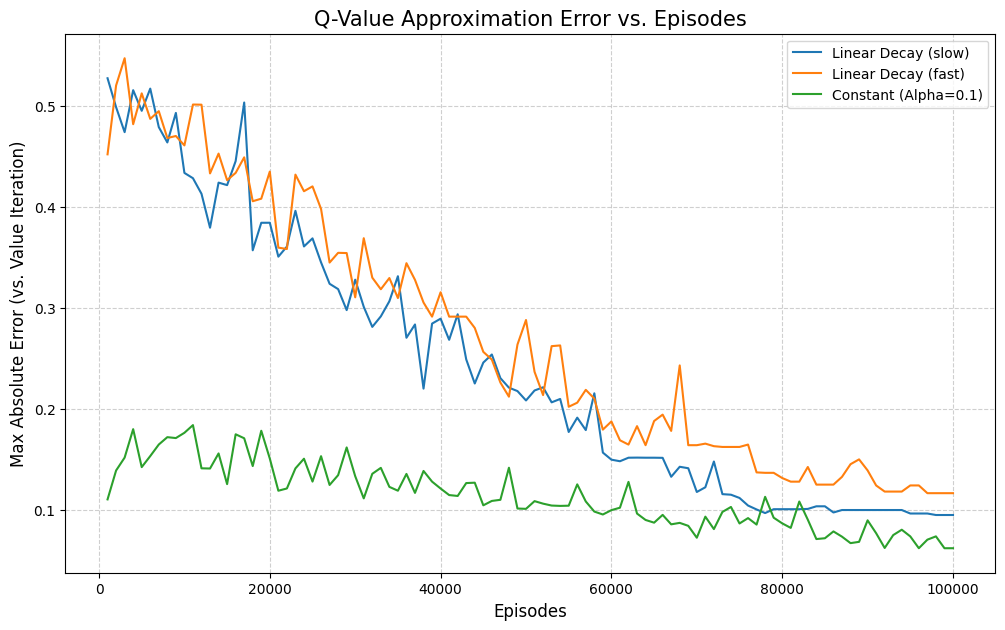

In [29]:
def get_schedulers():
    schedulers = {
        'Linear Decay (slow)': {
            'alpha': lambda ep, total: max(0.01, 0.5 * (1 - ep/total)),
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        },
        'Linear Decay (fast)': {
            'alpha': lambda ep, total: max(0.01, 0.5 * (1 - ep/total*0.8)),
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        },
        'Constant (Alpha=0.1)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        }
    }
    return schedulers

run_experiment()

Testing Scheduler: Constant (Alpha=0.1)...
Testing Scheduler: Constant (Alpha=0.5)...
Testing Scheduler: Constant (Alpha=0.9)...


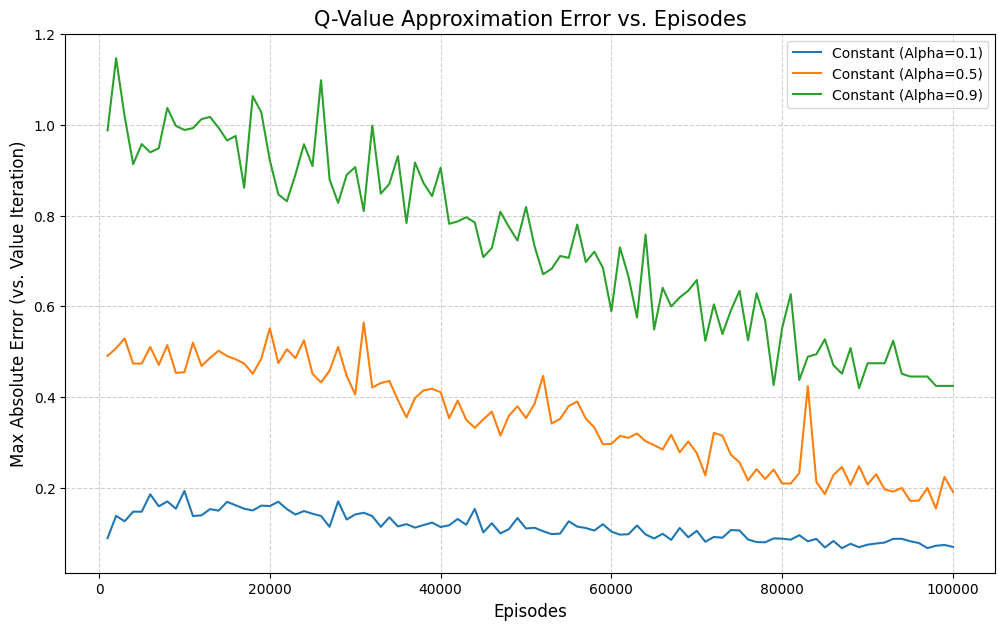

In [28]:
def get_schedulers():
    schedulers = {
        'Constant (Alpha=0.1)': {
            'alpha': lambda ep, total: 0.1,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        },
        'Constant (Alpha=0.5)': {
            'alpha': lambda ep, total: 0.5,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        },
        'Constant (Alpha=0.9)': {
            'alpha': lambda ep, total: 0.9,
            'epsilon': lambda ep, total: max(0.01, 1.0 * (1 - ep/total*0.8))
        }
    }
    return schedulers

run_experiment()